# Credit Card Fraud Detection — Enkhbayar Amarsanaa

## 파이프라인 구조
1. 데이터 로드 & 탐색  
2. 피처 엔지니어링  
3. Train / Test 분리 (고정)  
4. 불균형 처리 (`scale_pos_weight`)  
5. XGBoost 튜닝  
6. 임계값 최적화  
7. 최종 평가

> **Evaluation note (added for this repository)**
> - The metric printed as **ROC-AUC** is computed with `sklearn.metrics.roc_auc_score`. In the original run it was mislabelled "AUC-PR"; the labels in the code and printed output have been corrected, but the embedded chart images were rendered before the fix and still read "AUC-PR".
> - Early stopping (`eval_set`) and the F1-optimal decision threshold both use the 2020-07 → 2020-12 hold-out set, so the reported hold-out scores are somewhat optimistic. A stricter protocol would carve a validation window out of the training period (e.g. 2020-04 → 2020-06) for early stopping and threshold selection.


## 1. 라이브러리 & 유틸리티

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle, warnings
warnings.filterwarnings('ignore')

# Korean-capable font for plot labels (falls back silently if none is installed)
import matplotlib.font_manager as fm
_available = {f.name for f in fm.fontManager.ttflist}
for _font in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if _font in _available:
        plt.rcParams['font.family'] = _font
        break
plt.rcParams['axes.unicode_minus'] = False

from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, precision_recall_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score

# ── pickle 유틸 ──
def pickle_save(data, file_name):
    with open(file_name, 'wb') as f:
        pickle.dump(data, f)

def pickle_load(file_name):
    with open(file_name, 'rb') as f:
        return pickle.load(f)

print("라이브러리 로드 완료")

라이브러리 로드 완료


## 2. 데이터 로드 & 기본 탐색

In [2]:
import os

# Local path (default) — override with the FRAUD_DATA_PATH environment variable.
DATA_PATH = os.environ.get("FRAUD_DATA_PATH") or next(
    (p for p in ["../data/fraud_data.pkl", "data/fraud_data.pkl"] if os.path.exists(p)),
    "../data/fraud_data.pkl")

# On Google Colab, fall back to the copy in Google Drive.
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA_PATH = '/content/drive/MyDrive/datasets/fraud_data.pkl'
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} not found — see README.md (Data section).")

data = pickle_load(DATA_PATH)
print("Shape:", data.shape)
data.head()


Mounted at /content/drive
Shape: (1852394, 23)


,amt,city_pop,is_fraud,count,amt_z_score,cat_z_score,distance,distance_z_score,age,category_food_dining,...,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel,gender_M
trans_date_trans_time,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:18,4.97,3495,0,2927,-0.662108,-0.688297,78.773821,0.030974,33,False,...,False,False,False,True,False,False,False,False,False,False
2019-01-01 00:00:44,107.23,149,0,4362,0.321302,0.317631,30.216618,-1.475224,43,False,...,False,False,False,False,False,False,False,False,False,False
2019-01-01 00:00:51,220.11,4154,0,735,1.287064,2.872509,108.102912,1.160572,59,False,...,False,False,False,False,False,False,False,False,False,True
2019-01-01 00:01:16,45.00,1939,0,743,-0.125287,-1.050197,95.685115,0.818063,54,False,...,False,False,False,False,False,False,False,False,False,True
2019-01-01 00:03:06,41.96,99,0,2922,-0.565941,1.312866,77.702395,0.064037,35,False,...,False,False,False,False,True,False,False,False,False,True


In [3]:
print("컬럼 목록:")
print(data.columns.tolist())
print()
print("결측값:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print()
print("타겟 분포:")
print(data['is_fraud'].value_counts())
print(f"사기 비율: {data['is_fraud'].mean():.4%}")

컬럼 목록:
['amt', 'city_pop', 'is_fraud', 'count', 'amt_z_score', 'cat_z_score', 'distance', 'distance_z_score', 'age', 'category_food_dining', 'category_gas_transport', 'category_grocery_net', 'category_grocery_pos', 'category_health_fitness', 'category_home', 'category_kids_pets', 'category_misc_net', 'category_misc_pos', 'category_personal_care', 'category_shopping_net', 'category_shopping_pos', 'category_travel', 'gender_M']

결측값:
cat_z_score    219
dtype: int64

타겟 분포:
is_fraud
0    1842743
1       9651
Name: count, dtype: int64
사기 비율: 0.5210%


## 3. 피처 엔지니어링

### 전략
- **카테고리 피처**: XGBoost에서 가장 중요한 `category_grocery_pos` 등 이미 one-hot 인코딩된 카테고리 활용
- **금액 비율 피처**: 카테고리/고객별 평균 대비 비율 → 이상 거래 탐지에 효과적
- **시간 피처**: 밤·새벽 시간대, 요일 → 사기는 특정 시간에 집중
- **결측 플래그**: `cat_z_score` 결측 자체가 사기 신호일 수 있음

In [5]:
df = data.copy()

# ── 3-1. 결측 플래그 (결측 자체가 신호) ──
df['cat_z_null'] = df['cat_z_score'].isnull().astype(int)

# cat_z_score 결측 → 전체 평균으로 대체 (cat 컬럼 없음, category_* one-hot 인코딩됨)
df['cat_z_score'] = df['cat_z_score'].fillna(df['cat_z_score'].mean())

# ── 3-2. 카테고리 역산 (amt 비율 피처용) ──
# category_* one-hot 컬럼으로 카테고리 레이블 복원
cat_cols = [c for c in df.columns if c.startswith('category_')]
# one-hot → category label (no active flag = the dropped baseline category → 'other')
df['cat'] = np.select([df[c].astype(bool) for c in cat_cols],
                     [c.replace('category_', '') for c in cat_cols], default='other')

# 카테고리 평균/중앙값 대비 비율 → 해당 카테고리에서 얼마나 이상한 금액인지
df['amt_cat_mean_ratio']   = df['amt'] / df.groupby('cat')['amt'].transform('mean')
df['amt_cat_median_ratio'] = df['amt'] / df.groupby('cat')['amt'].transform('median')

# 전체 평균 대비 비율
df['amt_global_ratio'] = df['amt'] / df['amt'].mean()

# 금액 로그 변환 (스케일 안정화)
df['amt_log'] = np.log1p(df['amt'])

# cat 컬럼 제거 (문자열이라 모델 입력 불가)
df = df.drop(columns=['cat'])

# ── 3-3. 시간 피처 (index가 datetime) ──
if pd.api.types.is_datetime64_any_dtype(df.index):
    df['hour']        = df.index.hour
    df['dayofweek']   = df.index.dayofweek  # 0=월, 6=일
    df['is_night']    = ((df['hour'] >= 22) | (df['hour'] <= 5)).astype(int)
    df['is_weekend']  = (df['dayofweek'] >= 5).astype(int)
    df['night_weekend'] = df['is_night'] * df['is_weekend']

# ── 3-4. 인구 밀도 대비 금액 ──
if 'city_pop' in df.columns:
    df['amt_per_pop'] = df['amt'] / (df['city_pop'] + 1)

print("피처 엔지니어링 완료")
print("현재 컬럼 수:", df.shape[1])
df.head(3)

피처 엔지니어링 완료
현재 컬럼 수: 34


,amt,city_pop,is_fraud,count,amt_z_score,cat_z_score,distance,distance_z_score,age,category_food_dining,...,amt_cat_mean_ratio,amt_cat_median_ratio,amt_global_ratio,amt_log,hour,dayofweek,is_night,is_weekend,night_weekend,amt_per_pop
trans_date_trans_time,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:18,4.97,3495,0,2927,-0.662108,-0.688297,78.773821,0.030974,33,False,...,0.061984,0.503546,0.070936,1.786747,0,1,1,0,0,0.001422
2019-01-01 00:00:44,107.23,149,0,4362,0.321302,0.317631,30.216618,-1.475224,43,False,...,0.919323,1.020849,1.530467,4.684259,0,1,1,0,0,0.714867
2019-01-01 00:00:51,220.11,4154,0,735,1.287064,2.872509,108.102912,1.160572,59,False,...,3.431553,4.328614,3.141576,5.398660,0,1,1,0,0,0.052975


## 4. Train / Test 분리 (고정)
> 시계열 기반 분리: 2020-07-01 이전 = train, 이후 = test  
> **이 분리는 변경하지 않음**

In [6]:
train = df[df.index < '2020-07-01']
test  = df[df.index >= '2020-07-01']

# 타겟 분리
y_train = train['is_fraud']
y_test  = test['is_fraud']

# 입력 피처 (문자열 컬럼 제거)
drop_cols = ['is_fraud']
# 잔여 object 컬럼 제거 (cat 등 원본 문자열)
obj_cols = [c for c in df.columns if df[c].dtype == 'object']
drop_cols += obj_cols

X_train = train.drop(columns=drop_cols, errors='ignore')
X_test  = test.drop(columns=drop_cols, errors='ignore')

print(f"Train: {X_train.shape}  |  사기 비율: {y_train.mean():.4%}")
print(f"Test : {X_test.shape}   |  사기 비율: {y_test.mean():.4%}")
print()
print("사용 피처:", X_train.columns.tolist())

Train: (1326733, 33)  |  사기 비율: 0.5758%
Test : (525661, 33)   |  사기 비율: 0.3828%

사용 피처: ['amt', 'city_pop', 'count', 'amt_z_score', 'cat_z_score', 'distance', 'distance_z_score', 'age', 'category_food_dining', 'category_gas_transport', 'category_grocery_net', 'category_grocery_pos', 'category_health_fitness', 'category_home', 'category_kids_pets', 'category_misc_net', 'category_misc_pos', 'category_personal_care', 'category_shopping_net', 'category_shopping_pos', 'category_travel', 'gender_M', 'cat_z_null', 'amt_cat_mean_ratio', 'amt_cat_median_ratio', 'amt_global_ratio', 'amt_log', 'hour', 'dayofweek', 'is_night', 'is_weekend', 'night_weekend', 'amt_per_pop']


## 5. 불균형 처리 전략

### 왜 `scale_pos_weight`를 쓰는가?
- SMOTE는 합성 샘플을 생성해 훈련 속도 저하 + 과적합 위험
- XGBoost의 `scale_pos_weight` = (음성 수 / 양성 수)  
  → 내부적으로 사기 샘플에 더 높은 가중치 부여, 데이터 증가 없음  
- 사기 탐지처럼 **극단적 불균형** 데이터에서 더 안정적

In [7]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"정상 거래: {neg_count:,}")
print(f"사기 거래: {pos_count:,}")
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

정상 거래: 1,319,094
사기 거래: 7,639
scale_pos_weight = 172.68


## 6. XGBoost 튜닝

### 튜닝 포인트
| 파라미터 | 역할 |
|---|---|
| `scale_pos_weight` | 불균형 보정 |
| `max_depth` | 트리 복잡도 (과적합 방지) |
| `learning_rate` | 학습률 낮출수록 일반화 ↑ |
| `subsample` | 행 샘플링 비율 (과적합 방지) |
| `colsample_bytree` | 컬럼 샘플링 비율 |
| `min_child_weight` | 리프 노드 최소 가중치 |
| `n_estimators` | 트리 개수 (early stopping과 함께 설정) |

In [12]:
xgb_model_simple = XGBClassifier()

In [14]:
xgb_model_simple.fit(
    X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [15]:
y_pred_simple = xgb_model_simple.predict(X_test)

print("=" * 50)
print("기본 XGBoost 성능")
print("=" * 50)
print(classification_report(y_test, y_pred_simple, target_names=['정상', '사기']))

기본 XGBoost 성능
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.90      0.78      0.83      2012

    accuracy                           1.00    525661
   macro avg       0.95      0.89      0.92    525661
weighted avg       1.00      1.00      1.00    525661



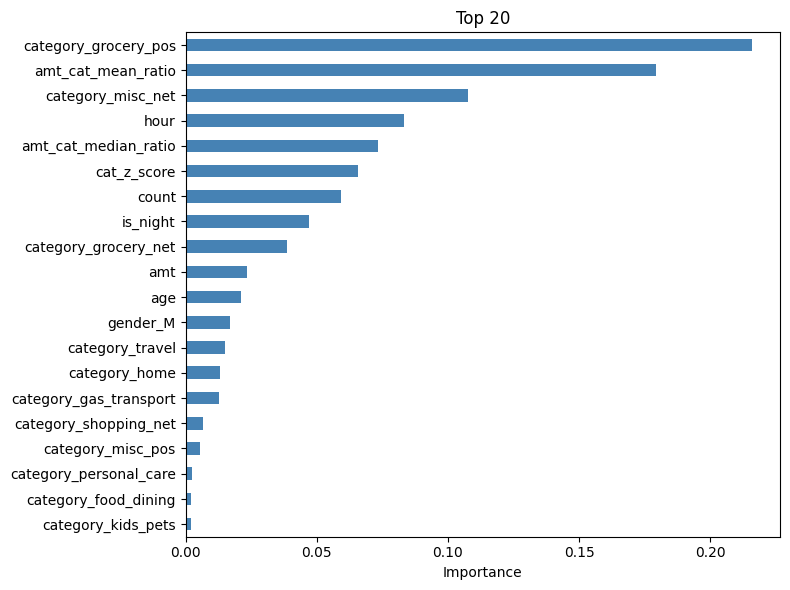

In [18]:
importance = pd.Series(xgb_model_simple.feature_importances_, index=X_train.columns)
top20 = importance.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
top20.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 20')
plt.xlabel('Importance')
plt.tight_layout(); plt.show()

In [8]:
xgb_model = XGBClassifier(
    # ── 불균형 처리 ──
    scale_pos_weight = scale_pos_weight,

    # ── 트리 구조 ──
    n_estimators     = 500,
    max_depth        = 6,
    learning_rate    = 0.05,

    # ── 정규화 (과적합 방지) ──
    subsample        = 0.8,
    colsample_bytree = 0.8,
    min_child_weight = 5,
    gamma            = 1,

    # ── 기타 ──
    eval_metric      = 'aucpr',   # precision-recall AUC (불균형에 적합)
    early_stopping_rounds = 30,
    random_state     = 42,
    n_jobs           = -1,
    verbosity        = 1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)
print("\n훈련 완료 |  사용된 트리 수:", xgb_model.best_iteration)

[0]	validation_0-aucpr:0.38113
[50]	validation_0-aucpr:0.74859
[100]	validation_0-aucpr:0.83807
[150]	validation_0-aucpr:0.86944
[200]	validation_0-aucpr:0.88215
[250]	validation_0-aucpr:0.88414
[300]	validation_0-aucpr:0.88650
[350]	validation_0-aucpr:0.88792
[400]	validation_0-aucpr:0.88871
[450]	validation_0-aucpr:0.89151
[481]	validation_0-aucpr:0.89122

훈련 완료 |  사용된 트리 수: 451


## 7. 임계값(Threshold) 최적화

기본 0.5 임계값은 불균형 데이터에서 최적이 아닐 수 있음.  
Precision-Recall 곡선에서 **F1이 최대가 되는 임계값**을 탐색.

최적 임계값: 0.9796
해당 임계값에서 F1: 0.8393
Precision: 0.8916  |  Recall: 0.7927


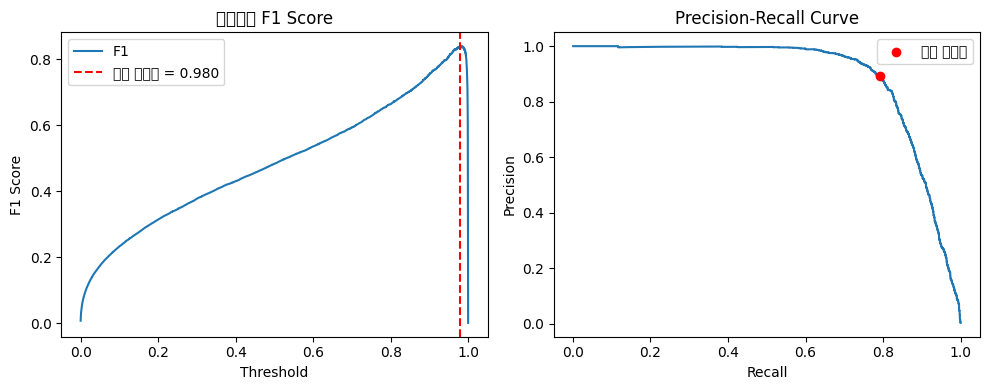

In [9]:
# 확률 예측
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# Precision-Recall 곡선
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
f1_scores = 2 * precision * recall / (precision + recall + 1e-9)
best_idx  = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"최적 임계값: {best_threshold:.4f}")
print(f"해당 임계값에서 F1: {f1_scores[best_idx]:.4f}")
print(f"Precision: {precision[best_idx]:.4f}  |  Recall: {recall[best_idx]:.4f}")

# 시각화
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(thresholds, f1_scores[:-1], label='F1')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'최적 임계값 = {best_threshold:.3f}')
plt.xlabel('Threshold'); plt.ylabel('F1 Score')
plt.title('임계값별 F1 Score'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(recall[:-1], precision[:-1])
plt.scatter(recall[best_idx], precision[best_idx], color='red', zorder=5, label='최적 임계값')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve'); plt.legend()
plt.tight_layout(); plt.show()

## 8. 최종 평가

최종 성능 (최적 임계값 적용)
              precision    recall  f1-score   support

          정상       1.00      1.00      1.00    523649
          사기       0.89      0.79      0.84      2012

    accuracy                           1.00    525661
   macro avg       0.95      0.90      0.92    525661
weighted avg       1.00      1.00      1.00    525661



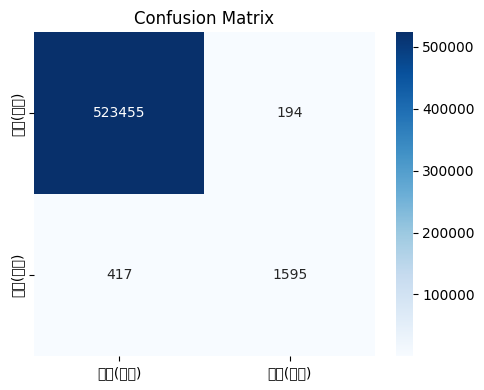


F1 (임계값 0.5):    0.4831
F1 (최적 임계값):   0.8393
F1 향상:            +0.3561


In [10]:
# 최적 임계값 적용
y_pred = (y_prob >= best_threshold).astype(int)

print("=" * 50)
print("최종 성능 (최적 임계값 적용)")
print("=" * 50)
print(classification_report(y_test, y_pred, target_names=['정상', '사기']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['정상(예측)', '사기(예측)'],
            yticklabels=['정상(실제)', '사기(실제)'])
plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

# 기본 임계값(0.5)과 비교
y_pred_default = (y_prob >= 0.5).astype(int)
f1_default  = f1_score(y_test, y_pred_default)
f1_optimized = f1_score(y_test, y_pred)
print(f"\nF1 (임계값 0.5):    {f1_default:.4f}")
print(f"F1 (최적 임계값):   {f1_optimized:.4f}")
print(f"F1 향상:            +{f1_optimized - f1_default:.4f}")

## 9. 피처 중요도

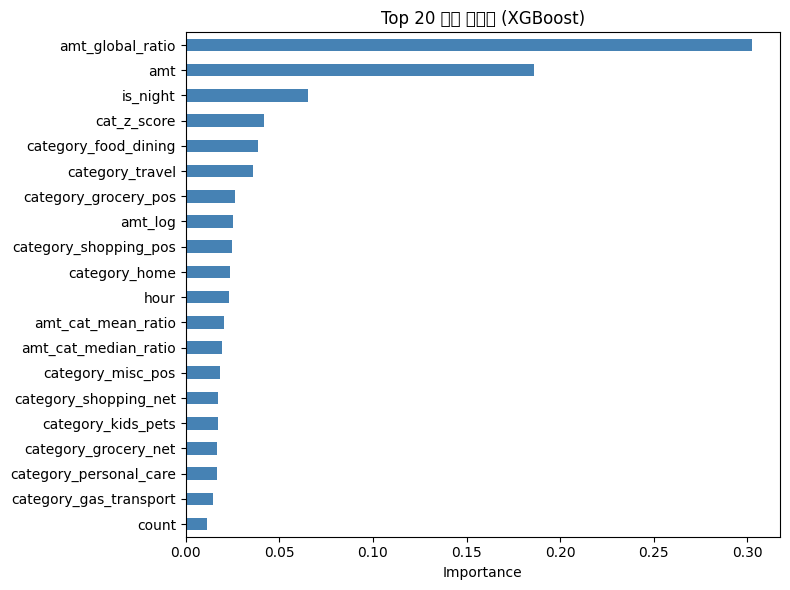

Top 10 피처:
amt_global_ratio         0.302248
amt                      0.186011
is_night                 0.065617
cat_z_score              0.041752
category_food_dining     0.038752
category_travel          0.035931
category_grocery_pos     0.026468
amt_log                  0.025472
category_shopping_pos    0.024549
category_home            0.023872
dtype: float32


In [11]:
importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
top20 = importance.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
top20.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 20 피처 중요도 (XGBoost)')
plt.xlabel('Importance')
plt.tight_layout(); plt.show()

print("Top 10 피처:")
print(top20.head(10))